# Classical pipeline: Gaussian filter, then intensity rescaling, then Canny (BTXRD)
Applies 3 classical methods to every X-ray, one after the other, **at its full size** (2440 x 2440), and only then makes it 512 x 512 (the same way as notebook 07).

1. **Gaussian filter** (noise reduction): 3 x 3 window, strength 0.8.
2. **Intensity rescaling** (normalization): the darkest 1% of the X-ray becomes black, the brightest 1% white.
3. **Canny** (edge enhancement): thin edge lines are drawn on the X-ray at half white.

Each step works on the result of the step before: X-ray → Gaussian → rescaling → Canny → 512 x 512. The settings and the code of each step are the same as in its own notebook (`gaussian_btxrd`, `rescaling_btxrd`, `canny_btxrd`), so the only new thing is that the 3 steps are combined.

**Why these 3 and this order.** For ResNet-18, these 3 methods were better than the raw images on both the validation and the test images. The order follows the usual pipeline: first remove noise, then make the brightness alike, then strengthen the edges. Canny finds its edges after the other 2 steps, on the image the model would get.

The new images are saved as PNG in **`BTXRD_gaussian_rescaling_canny_512.zip`**, in this folder. Inside the zip are the same `train`, `validation` and `test` folders, each with `normal` and `tumor`, as in `BTXRD_512.zip`. Every image stays in the same split as before.
The original data is only read, never changed.

## Settings

In [1]:
import io
import json
import zipfile
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

DATA = Path("../../../../data/BTXRD no duplicates")    # the original full-size images without duplicates (only read)
ANNOTATIONS = DATA / "Annotations"                     # tumor outlines (only read)
OLD_ZIP = Path("../../../../data/BTXRD_512.zip")       # the baseline zip (only read, to check the split)
NAME = "BTXRD_gaussian_rescaling_canny_512"            # the name of the new zip and of the folder inside it
NEW_ZIP = Path(NAME + ".zip")                          # the new zip is saved here, in this folder
SPLITS = ["train", "validation", "test"]
MALIGNANT = {"osteosarcoma", "other mt"}               # all other tumor types are benign

SIZE = (512, 512)    # the same size as the baseline
# step 1
GAUSSIAN_SIZE = 3      # Gaussian filter: 3 x 3 pixels
GAUSSIAN_SIGMA = 0.8   # how strong the blur is (0.8 is the value OpenCV uses for a 3 x 3 window)
# step 2
RESCALE_LOW = 1      # rescaling: the darkest 1% of the X-ray becomes black (0)
RESCALE_HIGH = 99    # rescaling: the brightest 1% of the X-ray becomes white (255)
# step 3
CANNY_SIGMA = 5      # Canny: the blur is 5 pixels wide on the full image (about 1 pixel on the 512 x 512 image)
HIGH_PERCENT = 90    # Canny: edges stronger than 90% of the X-ray's edge strengths are sure edges
LOW_RATIO = 0.4      # Canny: weaker edges (above 0.4 x the high threshold) count only if they connect to a sure edge
EDGE_WEIGHT = 0.5    # Canny: the edge lines are added at half white (0.5 x 255)
BLACK = 15           # pixels at or below this are black background
RING = 10            # CII: width of the ring around the tumor, in pixels (on the 512 x 512 image)

## List the images
Every image in the `train`, `validation` and `test` folders, with its split, label (normal or tumor) and group (normal, benign or malignant).

In [2]:
def tumor_type(path):
    annotation = ANNOTATIONS / (path.stem + ".json")
    if not annotation.exists():
        return ""                                              # normal images have no annotation
    return json.loads(annotation.read_text())["shapes"][0]["label"]


records = []
for split in SPLITS:
    for path in sorted((DATA / split).glob("*/*.jp*g")):       # */ = normal or tumor, files end in .jpeg or .jpg
        kind = tumor_type(path)
        if kind == "":
            group = "normal"
        elif kind in MALIGNANT:
            group = "malignant"
        else:
            group = "benign"
        records.append({"image": path.stem, "split": split, "label": path.parent.name, "group": group, "path": path})

images = pd.DataFrame(records)
print(len(images), "images")
print(images.groupby(["split", "label"]).size())

3723 images
split       label 
test        normal     280
            tumor      279
train       normal    1306
            tumor     1300
validation  normal     280
            tumor      278
dtype: int64


## Check: the same split as `BTXRD_512.zip`
Every image must be in the same split (train, validation or test) and have the same label as in the baseline zip. If not, the notebook stops here.

In [3]:
with zipfile.ZipFile(OLD_ZIP) as old_zip:
    old_names = {name.removeprefix("BTXRD_512/").removesuffix(".png")   # for example train/normal/IMG001868
                 for name in old_zip.namelist() if name.endswith(".png")}
names = set(images["split"] + "/" + images["label"] + "/" + images["image"])

print("Images in BTXRD_512.zip:", len(old_names), "| images here:", len(names))
print("Same split and label for every image:", names == old_names)
assert names == old_names, "the split is not the same as in BTXRD_512.zip"

Images in BTXRD_512.zip: 3723 | images here: 3723
Same split and label for every image: True


## Functions
Load an image at full size, the 3 steps (each copied from its own notebook), the pipeline that applies them one after the other, make it 512 x 512, and find the X-ray inside the black square.

In [4]:
def load(path):
    image = Image.open(path).convert("L")                      # gray, pixels 0 (black) to 255 (white)
    return np.array(image)                                     # full size: 2440 x 2440


def gaussian_filter(image):
    size = (GAUSSIAN_SIZE, GAUSSIAN_SIZE)
    return cv2.GaussianBlur(image, size, GAUSSIAN_SIGMA)       # every pixel gets a weighted average of the pixels around it (near pixels count more)


def rescale(image):
    xray = image[image > BLACK]                                # the X-ray pixels, not the black square
    low, high = np.percentile(xray, [RESCALE_LOW, RESCALE_HIGH])   # the gray value of the darkest 1% and of the brightest 1%
    stretched = (image.astype(np.float64) - low) / (high - low) * 255   # low -> 0, high -> 255, the rest evenly in between
    return np.clip(stretched, 0, 255).round().astype(np.uint8) # below low -> 0 (so the black square stays black), above high -> 255


def canny_edges(image):
    blurred = cv2.GaussianBlur(image, (0, 0), CANNY_SIGMA)           # Canny step 1: blur, so tiny pixel noise is not found as edges
    gx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)         # edge strength, measured the same way as inside cv2.Canny ...
    gy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
    strength = np.hypot(gx, gy)[image > BLACK]                 # ... on the X-ray only, not the black square
    high = np.percentile(strength, HIGH_PERCENT)               # the high threshold, chosen for this X-ray
    edges = cv2.Canny(blurred, LOW_RATIO * high, high, L2gradient=True)   # thin edge lines: 255 on an edge, 0 elsewhere
    enhanced = image + EDGE_WEIGHT * edges                     # the edge lines are drawn on the X-ray at half white
    return np.clip(enhanced, 0, 255).round().astype(np.uint8)  # keep the gray values between 0 and 255


def pipeline(image):
    step1 = gaussian_filter(image)                             # 1. noise reduction
    step2 = rescale(step1)                                     # 2. normalization, on the result of step 1
    step3 = canny_edges(step2)                                 # 3. edge enhancement, on the result of step 2
    return step3


def shrink(image):
    image = Image.fromarray(image).resize(SIZE, Image.LANCZOS)  # 512 x 512, the same way as notebook 07
    return np.array(image)


def xray_box(image):
    rows = np.where((image > BLACK).any(axis=1))[0]            # rows with something brighter than black
    cols = np.where((image > BLACK).any(axis=0))[0]            # the same for columns
    return rows[0], rows[-1] + 1, cols[0], cols[-1] + 1        # top, bottom, left, right

## Before and after each step: 2 normal, 2 benign, 2 malignant
All at 512 x 512, the size the models see. Each step is done on the full image, and only the picture is made smaller. Before = the baseline image (the same as in `BTXRD_512.zip`).

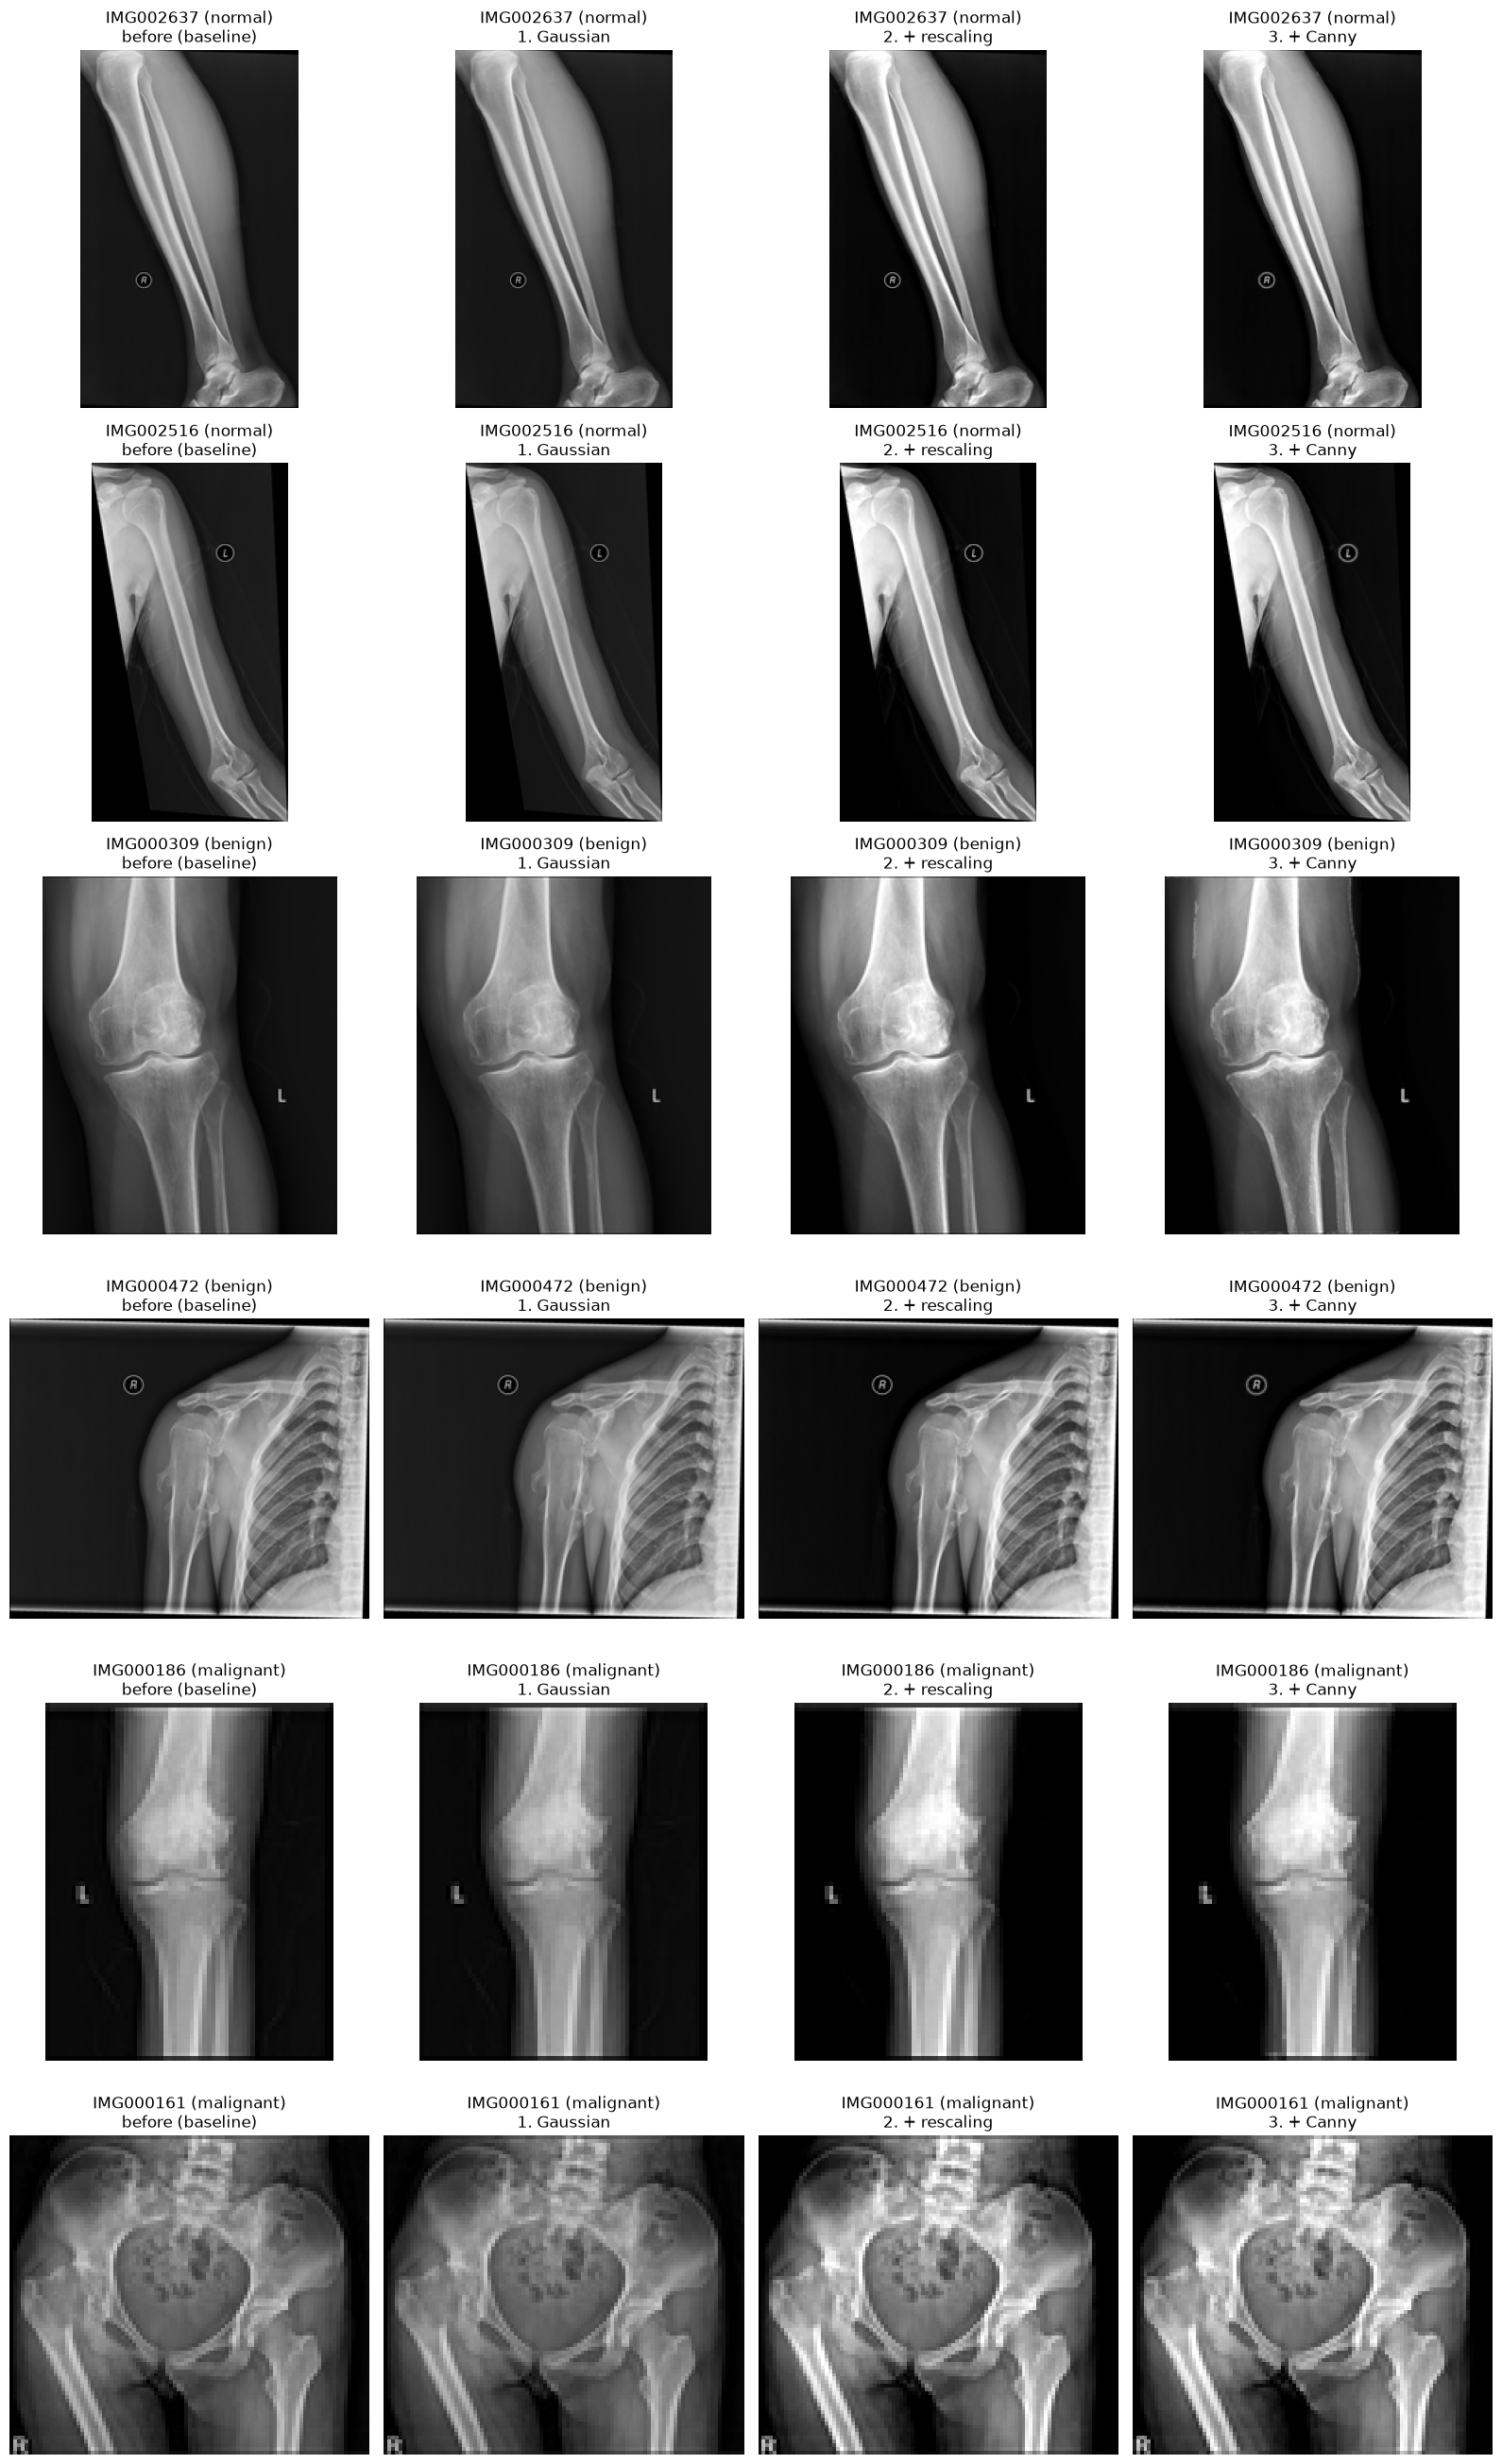

In [5]:
picks = pd.concat([images[images["group"] == group].sample(2, random_state=42)
                   for group in ["normal", "benign", "malignant"]])
titles = ["before (baseline)", "1. Gaussian", "2. + rescaling", "3. + Canny"]

fig, axes = plt.subplots(len(picks), 4, figsize=(16, 4.4 * len(picks)))
for row, (_, pick) in zip(axes, picks.iterrows()):
    raw = load(pick["path"])
    step1 = gaussian_filter(raw)                               # every step on the full image ...
    step2 = rescale(step1)
    step3 = canny_edges(step2)
    pictures = [shrink(raw), shrink(step1), shrink(step2), shrink(step3)]   # ... then 512 x 512
    assert np.array_equal(pictures[3], shrink(pipeline(raw)))  # the same as the pipeline function
    top, bottom, left, right = xray_box(pictures[0])           # cut away the black square, so the bone is big enough to see
    for ax, picture, title in zip(row, pictures, titles):
        ax.imshow(picture[top:bottom, left:right], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{pick['image']} ({pick['group']})\n{title}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## Measuring functions
Both images are compared at 512 x 512: the baseline image (before) and the new image (after).
- PSNR and SSIM: how much the image changed (higher = less change). Measured on the X-ray only, not the black square.
- CII: how much more the tumor stands out from the ring around it. Above 1 = it stands out more.

In [6]:
def tumor_mask(name):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = SIZE[0] / annotation["imageWidth"]                 # the outline was drawn on the 2440 x 2440 image
    mask = np.zeros((SIZE[1], SIZE[0]), dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around(tumor, before):
    kernel = np.ones((2 * RING + 1, 2 * RING + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background


def contrast(image, tumor, ring):
    t = image[tumor].mean()                                    # tumor brightness
    r = image[ring].mean()                                     # ring brightness
    return abs(t - r) / (t + r)                                # abs: a tumor can be darker or brighter than the bone


def cii(before, after, tumor, ring):
    if tumor.sum() == 0 or ring.sum() == 0:
        return np.nan                                          # cannot be measured
    contrast_before = contrast(before, tumor, ring)
    if contrast_before == 0:
        return np.nan                                          # cannot divide by 0
    return contrast(after, tumor, ring) / contrast_before


def psnr_ssim(before, after):
    top, bottom, left, right = xray_box(before)                # the X-ray only
    a, b = before[top:bottom, left:right], after[top:bottom, left:right]
    return peak_signal_noise_ratio(a, b, data_range=255), structural_similarity(a, b, data_range=255)

## Make every image, save it in the zip, and measure it
For every image: the 3 steps on the full image, then 512 x 512, then saved as PNG in the zip (`BTXRD_gaussian_rescaling_canny_512/split/label/name.png`).
Then PSNR, SSIM and CII against the baseline image. CII is only for tumor images. This takes some minutes.

In [7]:
rows = []
with zipfile.ZipFile(NEW_ZIP, "w") as new_zip:                 # "w": makes a new zip (an old one with the same name is replaced)
    for n, (_, item) in enumerate(images.iterrows(), start=1):
        raw = load(item["path"])
        before = shrink(raw)                                   # the baseline image
        after = shrink(pipeline(raw))                          # the 3 steps on the full image, then 512 x 512

        png = io.BytesIO()                                     # make the PNG file in memory ...
        Image.fromarray(after).save(png, format="PNG")
        new_zip.writestr(f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png", png.getvalue())   # ... and put it in the zip

        psnr, ssim = psnr_ssim(before, after)
        row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
        if item["label"] == "tumor":
            tumor = tumor_mask(item["image"])
            row["CII"] = cii(before, after, tumor, ring_around(tumor, before))
        rows.append(row)

        if n % 500 == 0:
            print(n, "of", len(images), "done")

scores = pd.DataFrame(rows)
print(len(images), "images saved in", NEW_ZIP)

500 of 3723 done
1000 of 3723 done
1500 of 3723 done
2000 of 3723 done
2500 of 3723 done
3000 of 3723 done
3500 of 3723 done
3723 images saved in BTXRD_gaussian_rescaling_canny_512.zip


## Check the new zip
Counts the images in each folder, checks that all are 512 x 512 gray images, and that every image is in the same split and label as in `BTXRD_512.zip`.

In [8]:
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    files = [name for name in new_zip.namelist() if name.endswith(".png")]
    sizes, modes = Counter(), Counter()
    for name in files:
        image = Image.open(new_zip.open(name))
        sizes[image.size] += 1
        modes[image.mode] += 1                                 # L = gray

for folder, count in sorted(Counter(name.rsplit("/", 1)[0] for name in files).items()):
    print(folder, count)
print("Sizes:", dict(sizes), "| modes:", dict(modes))
new_names = {name.removeprefix(NAME + "/").removesuffix(".png") for name in files}
print("Same images, split and label as BTXRD_512.zip:", new_names == old_names)
print("Zip size:", round(NEW_ZIP.stat().st_size / 1e6), "MB")

BTXRD_gaussian_rescaling_canny_512/test/normal 280
BTXRD_gaussian_rescaling_canny_512/test/tumor 279
BTXRD_gaussian_rescaling_canny_512/train/normal 1306
BTXRD_gaussian_rescaling_canny_512/train/tumor 1300
BTXRD_gaussian_rescaling_canny_512/validation/normal 280
BTXRD_gaussian_rescaling_canny_512/validation/tumor 278
Sizes: {(512, 512): 3723} | modes: {'L': 3723}
Same images, split and label as BTXRD_512.zip: True
Zip size: 73 MB


## Results
The middle value (median) of each score: the image after all 3 steps compared with the baseline image. CII only counts the tumor images.

In [9]:
scores[["PSNR", "SSIM", "CII"]].median().round(3)

PSNR    21.265
SSIM     0.767
CII      1.199
dtype: float64